# Liquid-state NMR in Hilbert space

This guide simulates free induction decays and spectra of small
liquid-state NMR spin systems with isotropic chemical shifts and
J-couplings in the Zeeman Hilbert-space formalism (`zeeman-hilb`). It is
the place to start; [Liouville space](liouville-space.ipynb) continues with
the spherical-tensor formalism and state-space restriction. Every stage reproduces Spinach 2.13 to rounding error; see
[Checking results against Spinach](#Checking-results-against-Spinach).

To run the examples interactively, open the companion notebook
[`notebooks/hilbert-space.ipynb`](hilbert-space.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/hilbert-space.ipynb)), generated from
this page. If you know Spinach, read
[Coming from Spinach](coming-from-spinach.ipynb) next: it lists, topic by
topic, what carries over unchanged and what is different.

Every Python block in this guide is executed by `tests/docs/`, in order and
in one namespace, so the examples stay correct as the code changes.

*Generated from [`docs/hilbert-space.md`](../hilbert-space.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Setup](#Setup)
2. [Quick start](#Quick-start)
3. [The simulation pipeline](#The-simulation-pipeline)
4. [Writing your own pulse sequence](#Writing-your-own-pulse-sequence)
5. [Plotting results](#Plotting-results)
6. [Tolerances](#Tolerances)
7. [Coming from Spinach](#Coming-from-Spinach)
8. [What is not ported yet](#What-is-not-ported-yet)
9. [Checking results against Spinach](#Checking-results-against-Spinach)

## Setup

Spynach needs Python 3.11 or later with NumPy, SciPy, and h5py. From the
repository root:

```
python -m pip install -e ".[test,docs]"
python -m pytest -q
```

The `docs` extra adds Plotly, JupyterLab, and what is needed to run the
notebooks; only plots and notebooks need it (`.[plot]` installs Plotly
alone). Start JupyterLab with `jupyter lab docs/notebooks/`.

A caveat for containers: when a container has a CPU quota below the number
of cores it can see (a 4-CPU quota on a 12-core host, say), OpenBLAS starts
one thread per visible core, oversubscribes the quota, and dense linear
algebra can run a thousand times slower. Set `OPENBLAS_NUM_THREADS` to the
quota in that case, for example `OPENBLAS_NUM_THREADS=4 jupyter lab`. On
an ordinary laptop or workstation nothing needs to be set.

## Quick start

Two coupled protons at 14.1 T (an AB system with a shift difference of
five times the coupling), simulated with a pulse-acquire experiment:

In [1]:
import numpy as np
import spynach

# Spin system: isotopes, field, chemical shifts (ppm), J-couplings (Hz)
sys = {"isotopes": ["1H", "1H"], "magnet": 14.1}
inter = {
    "zeeman": {"scalar": [1.00, 1.10]},
    "coupling": {"scalar": [[0, 12.0],
                            [0, 0]]},
}
spin_system = spynach.create(sys, inter)
spin_system = spynach.basis(spin_system, {"formalism": "zeeman-hilb", "approximation": "none"})

# Experiment: transverse proton magnetisation, detected on the same channel
parameters = {
    "spins": ["1H"],      # isotope of the working channel
    "offset": 630,        # transmitter offset, Hz
    "sweep": 200,         # spectral width, Hz (dwell time 1/sweep)
    "npoints": 1024,      # complex points in the FID
    "rho0": spynach.state(spin_system, "L+", "1H"),
    "coil": spynach.state(spin_system, "L+", "1H"),
}
fid = spynach.liquid(spin_system, spynach.acquire, parameters, "nmr")

# Spectrum: apodise (halve the first point, exponential window), zero-fill, Fourier transform
zerofill = 4096
fid = spynach.apodisation(fid, [("exp", 6)])
spectrum = np.fft.fftshift(np.fft.fft(fid, zerofill))

The frequency axis comes from `axis_1d`, a port of Spinach's function of
the same name: it runs from `offset - sweep/2` upwards in steps of
`sweep / zerofill`, and `axis_units` converts it to ppm with the carrier
frequency of the channel isotope:

In [2]:
from spynach.plotting import axis_1d

ppm_axis, label = axis_1d(spin_system, {**parameters, "zerofill": zerofill, "axis_units": "ppm"})

# Two doublets, split by J = 12 Hz, centred near the two chemical shifts
peaks = ppm_axis[spectrum.real > 0.5 * spectrum.real.max()]
print(f"{label}: lines between {peaks.min():.2f} and {peaks.max():.2f}")

1H chemical shift / ppm: lines between 0.99 and 1.11


`plot_1d` draws the spectrum on that axis, decreasing from left to right as
is usual in NMR. The figure is interactive: hover to read off shifts and
intensities, drag to zoom in, double-click to zoom out.

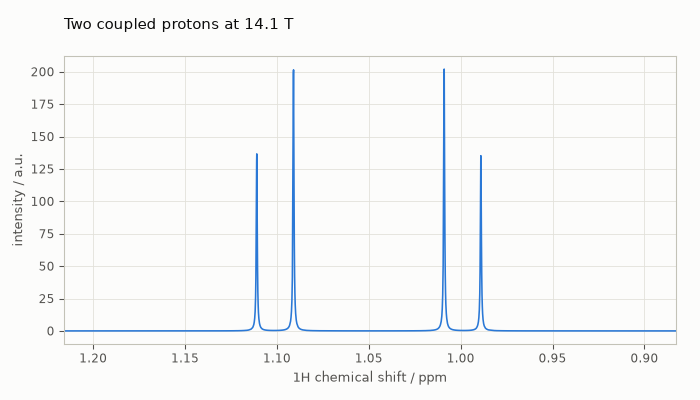

In [3]:
from spynach.plotting import plot_1d

plot_1d(spin_system, spectrum.real, parameters, title="Two coupled protons at 14.1 T")

`plot_fid` shows the time domain, real and imaginary parts:

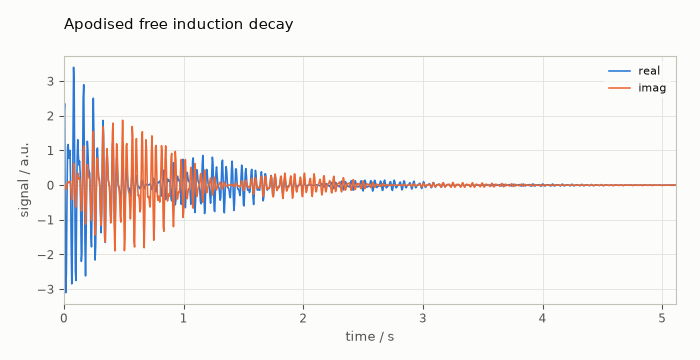

In [4]:
from spynach.plotting import plot_fid

plot_fid(fid, parameters, title="Apodised free induction decay")

Blocks that plot are the only ones that need Plotly; they define no names
that later blocks use. [Plotting results](#Plotting-results) has more.

## The simulation pipeline

A simulation runs through the same stages as in Spinach. Each function
returns a new object; nothing is modified in place.

```
create -> basis -> operator / state -> assume -> hamiltonian -> frqoffset -> propagator / evolution
                                       \__________________ liquid + acquire __________________/
```

### 1. `create`: describe the spin system

`spynach.create(sys, inter)` takes two dictionaries mirroring Spinach's `sys`
and `inter` structures.

| key | meaning | units |
|---|---|---|
| `sys["isotopes"]` | list of isotope names, e.g. `"1H"`, `"13C"`, `"2H"`, `"E"` | |
| `sys["magnet"]` | magnetic induction | Tesla |
| `sys["labels"]` | optional per-spin labels | |
| `sys["tols"]` | optional tolerance overrides, see [Tolerances](#Tolerances) | |
| `inter["zeeman"]["scalar"]` | per-spin chemical shift (nuclei) or isotropic g-value (electrons); `None` for none | ppm / Bohr magneton |
| `inter["zeeman"]["matrix"]` | per-spin 3x3 shift or g-tensor; `None` for none | ppm / Bohr magneton |
| `inter["coupling"]["scalar"]` | nspins x nspins nested list of J-couplings; `None` or 0 for none | Hz |
| `inter["coupling"]["matrix"]` | nspins x nspins nested list of 3x3 coupling tensors | Hz |
| `inter["chem"]["parts"]` | chemical subsystems: one list of spin indices per molecule | |
| `inter["chem"]["concs"]` | their initial concentrations (required for more than one part) | any, consistent |
| `inter["chem"]["rates"]` | first-order exchange rate matrix between the parts, `dc/dt = rates @ c` | Hz |

Enter each coupling once per pair, above or below the diagonal; values given
in both places are added together, as in Spinach. Any other key raises
`NotImplementedError`.

Chemical subsystems describe several molecules in one spin system: every
spin belongs to exactly one part, couplings never cross parts, and the
default is a single part holding all spins at unit concentration. The
exchange matrix must conserve matter (columns sum to zero) and, since
exchange moves spin states between molecules, the parts must list the same
isotopes in the same order. The information is kept in `spin_system.chem`; the
kinetics superoperator and exchanging systems need the Liouville-space
formalism, which is not ported yet.

In [5]:
spin_system_exchange = spynach.create(
    {"isotopes": ["1H", "1H"], "magnet": 14.1},
    {"zeeman": {"scalar": [0.0, 3.0]},
     "chem": {"parts": [[0], [1]], "rates": [[-2e3, 2e3], [2e3, -2e3]], "concs": [1.0, 1.0]}},
)
print(spin_system_exchange.chem.parts)
print(spin_system_exchange.chem.rates.sum(axis=0))     # conservation of matter: columns sum to zero

((0,), (1,))
[0. 0.]


The result is a frozen `SpinSystem`. Internally everything is in angular
frequency units (rad/s) in the laboratory frame:

In [6]:
spin_system = spynach.create(
    {"isotopes": ["1H", "13C"], "magnet": 14.1},
    {"zeeman": {"scalar": [2.00, 30.0]}, "coupling": {"scalar": [[0, 145.0], [0, 0]]}},
)
print(spin_system.nspins, spin_system.mults.tolist())  # number of spins, multiplicities 2S+1
carrier_mhz = spin_system.basefrqs / (2 * np.pi) / 1e6  # -gamma*B0, rad/s -> MHz
print(carrier_mhz.round(1))
print(spin_system.coupling_matrix[1][0])                # absent couplings are None

2 [2, 2]
[-600.3 -151. ]
None


Isotope data (multiplicity and magnetogyric ratio) come from Spinach's
`spin.m`: `spynach.isotopes.spin("15N")` returns `(gamma, multiplicity)`.

### 2. `basis`: choose the formalism

In [7]:
spin_system = spynach.basis(spin_system, {"formalism": "zeeman-hilb", "approximation": "none"})
print(spin_system.basis.basis)    # dim x nspins Zeeman level table

[[1 1]
 [1 2]
 [2 1]
 [2 2]]


`zeeman-hilb` works with the full Hilbert space of dimension
`prod(mults)`; matrices are `dim x dim`. It suits systems up to roughly ten
spin-1/2 particles. Basis states are Zeeman product states with the first
spin varying slowest, matching `np.kron(op_spin0, op_spin1)`.

### 3. `operator` and `state`: spin operators

Operators are built from a label and a spin selection. **Spin indices are
0-based.** There are three forms:

In [8]:
Lz_H = spynach.operator(spin_system, "Lz", "1H")          # sum over all 1H spins
Lz_01 = spynach.operator(spin_system, "Lz", [0, 1])       # sum over spins 0 and 1
LzSp = spynach.operator(spin_system, ["Lz", "L+"], [0, 1]) # product Lz(0) L+(1)

A string as the first argument means a sum of single-spin operators; a list
means a product operator with one label per listed spin. The spin selection
in the sum form can also be `"all"`, `"nuclei"`, or `"electrons"`.

| label | operator |
|---|---|
| `E` | unit operator |
| `Lz`, `Lx`, `Ly` | Cartesian spin operators |
| `L+`, `L-` | raising and lowering operators |
| `Tl,m` | irreducible spherical tensor, e.g. `T2,-1` |

`operator` returns a SciPy sparse matrix (`scipy.sparse.csr_array`, complex).
`state` takes the same arguments and, in Hilbert space, returns the same
matrix, used as an (unnormalised) density matrix:

In [9]:
rho = spynach.state(spin_system, "L+", "1H")

### 4. `assume` and `hamiltonian`: the Hamiltonian

`assume` decides which terms of each interaction survive. The `"nmr"`
assumption set is the usual high-field liquid-state approximation:

- rotating frame for every isotope (carrier frequencies removed),
- secular Zeeman terms,
- full (strong) J-coupling between spins of the same isotope,
- weak (LzSz) J-coupling between different isotopes.

`hamiltonian` then returns the isotropic Hamiltonian in rad/s:

In [10]:
H = spynach.hamiltonian(spynach.assume(spin_system, "nmr"))
H_zeeman = spynach.hamiltonian(spynach.assume(spin_system, "nmr", "zeeman"))      # drop couplings
H_coupling = spynach.hamiltonian(spynach.assume(spin_system, "nmr", "couplings")) # drop Zeeman terms

Small Hamiltonians come back as dense NumPy arrays, large sparse ones as
`csr_array`, following Spinach's `clean_up` rules (dimension below
`tols.small_matrix`, or density above `tols.dense_matrix`, means dense).
Every element is rounded to a grid of `tols.liouv_zero` (1e-10 rad/s).

### 5. `frqoffset`: transmitter offsets

The rotating frame of `"nmr"` puts each isotope's carrier at zero frequency.
`frqoffset` moves the frame by `parameters["offset"]` Hz on the channels in
`parameters["spins"]`, so that the spectral window is centred where the
signals are:

In [11]:
H_off = spynach.frqoffset(spin_system, H, {"spins": ["1H"], "offset": 1200})

`liquid` applies this for you.

### 6. `propagator` and `evolution`: time propagation

In [12]:
dt = 1 / 500
P = spynach.propagator(spin_system, H_off, dt)       # expm(-1j * H_off * dt)

rho0 = spynach.state(spin_system, "L+", "1H")
coil = spynach.state(spin_system, "L+", "1H")
# nsteps + 1 = 1024 points, from t = 0
fid_hc = spynach.evolution(spin_system, H_off, rho0, dt, 1023, "observable", coil=coil)

`evolution(..., "observable")` returns `hdot(coil, rho(t))` (the
Hilbert-Schmidt product, `sum(conj(coil) * rho)`) at `nsteps + 1` time
points. Below dimension `tols.small_matrix` (200) the propagator is a dense
Pade exponential; above it, Spinach's scaled and squared Taylor series with
rounding to `tols.prop_chop`, which keeps sparse propagators sparse.

### 7. `liquid` and `acquire`: the high-level route

`liquid(spin_system, sequence, parameters, "nmr")` runs `assume`, `hamiltonian`, and
`frqoffset`, and then calls `sequence(spin_system, parameters, H, R, K)`. R and K are
the relaxation and chemical kinetics superoperators; neither is ported yet,
so both are zero matrices, which is what Spinach gives when a system
specifies neither.

`acquire` is the simplest sequence: it evolves `parameters["rho0"]` for
`parameters["npoints"]` points at dwell time `1 / parameters["sweep"]` and
detects `parameters["coil"]`. It reproduces the step-by-step route above:

In [13]:
fid_liquid = spynach.liquid(
    spin_system, spynach.acquire,
    {"spins": ["1H"], "offset": 1200, "sweep": 500, "npoints": 1024, "rho0": rho0, "coil": coil},
    "nmr",
)

## Writing your own pulse sequence

A pulse sequence is any function with the signature
`sequence(spin_system, parameters, H, R, K)`. This one starts from
longitudinal magnetisation, applies an ideal 90-degree pulse about y, and
acquires:

In [14]:
def pulse_acquire(spin_system, parameters, H, R, K):
    L = H + 1j * R + 1j * K
    Ly = spynach.operator(spin_system, "Ly", parameters["spins"][0])
    pulse = spynach.propagator(spin_system, Ly, np.pi / 2)   # rotation angle as "time"
    rho = pulse @ parameters["rho0"] @ pulse.conj().T
    return spynach.evolution(
        spin_system, L, rho, 1 / parameters["sweep"], parameters["npoints"] - 1, "observable",
        coil=parameters["coil"],
    )

pars = {"spins": ["1H"], "offset": 1200, "sweep": 500, "npoints": 1024,
        "rho0": spynach.state(spin_system, "Lz", "1H"), "coil": spynach.state(spin_system, "L+", "1H")}
fid_pulse = spynach.liquid(spin_system, pulse_acquire, pars, "nmr")

# The pulse turns Lz into Lx = (L+ + L-)/2; only the L+ half is detected
print(np.allclose(fid_pulse, 0.5 * fid_liquid))

True


`propagator(spin_system, A, angle)` with a Hermitian operator `A` returns
`expm(-1j * angle * A)`, so a spin operator and a rotation angle give an
ideal pulse.

## Plotting results

`spynach.plotting` draws interactive [Plotly](https://plotly.com/python/)
figures that render in JupyterLab, VS Code, and exported HTML:

| function | draws | Spinach |
|---|---|---|
| `plot_1d(spin_system, spectrum, parameters)` | one or more 1D spectra | `plot_1d` |
| `plot_fid(fid, parameters)` | one or more FIDs against time | (none) |
| `axis_1d(spin_system, parameters)` | the frequency axis and its label, no plot | `axis_1d` |
| `ft_axis(offset, sweep, npoints)` | the Hz axis of an FFT | `ft_axis` |
| `figure_png(fig)` | PNG bytes of any of these figures (Kaleido, or a Matplotlib redraw) | `print -dpng` |

`plot_1d` reads the same `parameters` as Spinach's: `spins`, `offset`,
`sweep`, `axis_units` (default `"ppm"`; also `"Hz"`, `"kHz"`, `"MHz"`,
`"points"`, and the EPR units), and `invert_axis` (default 1, frequency
decreasing to the right). `zerofill` defaults to the length of the spectrum.
Pass several spectra as a list, or as a 2-D array with one per column, to
overlay them; complex data are drawn as real and imaginary parts.

Both plotting functions return a `plotly.graph_objects.Figure`. A figure
that is the last expression of a notebook cell is displayed;
`fig.update_xaxes(range=...)` and the other Plotly methods adjust it,
`fig.write_html("spectrum.html")` saves an interactive copy, and
`theme="dark"` suits dark notebook themes.

Back to the 1H-13C pair: the spectra from the two sequences above, on a Hz
axis, show the 145 Hz one-bond coupling and the factor of two between them:

In [15]:
window = np.exp(-np.arange(1024) / 256)
spectra = [np.fft.fftshift(np.fft.fft(f * window, 4096)).real for f in (fid_liquid, fid_pulse)]
pars_hc = {"spins": ["1H"], "offset": 1200, "sweep": 500, "axis_units": "Hz"}

hz, _ = axis_1d(spin_system, {**pars_hc, "zerofill": 4096})
low, high = hz[hz < 1200][np.argmax(spectra[0][hz < 1200])], hz[hz > 1200][np.argmax(spectra[0][hz > 1200])]
print(f"doublet splitting {high - low:.1f} Hz, peak height ratio {spectra[1].max() / spectra[0].max():.2f}")

doublet splitting 145.0 Hz, peak height ratio 0.50


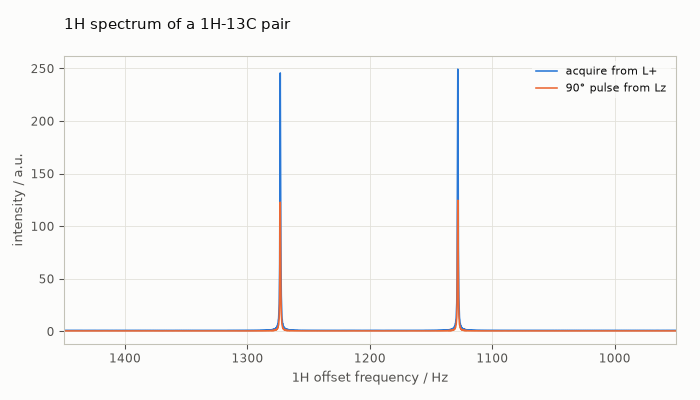

In [16]:
from spynach.plotting import plot_1d

plot_1d(spin_system, spectra, pars_hc, names=["acquire from L+", "90° pulse from Lz"],
        title="1H spectrum of a 1H-13C pair")

## Tolerances

`spin_system.tols` holds Spinach's numerical thresholds with their "safe default"
values. Override any of them at creation:

In [17]:
spin_system_fine = spynach.create({"isotopes": ["1H"], "magnet": 14.1, "tols": {"prop_chop": 1e-14}}, {})
print(spin_system_fine.tols.prop_chop, spin_system_fine.tols.small_matrix)

1e-14 200


The ones that matter for the ported code:

| tolerance | default | effect |
|---|---|---|
| `inter_cutoff` | 1e-10 | interactions weaker than this (Hz) are dropped |
| `liouv_zero` | 1e-10 | Hamiltonian elements are rounded to this grid (rad/s) |
| `prop_chop` | 1e-10 | Taylor-series terms and propagators are rounded to this grid |
| `small_matrix` | 200 | below this dimension matrices are dense and `expm` is used |
| `dense_matrix` | 0.15 | sparse matrices denser than this are made dense |

For propagators above `small_matrix`, the rounding error grows with the
number of squaring steps: about 1e-7 relative at the default `prop_chop`
for a step of norm 100. Lower `prop_chop` if you need more.

## Coming from Spinach

Function names, argument order, field names, and units are Spinach's. The
main differences: spin indices are 0-based, `sys`, `inter`, `bas`, and
`parameters` are dictionaries, spin systems are immutable, matrix products
are written `A @ B`, and time-domain results are 1-D arrays.
[Coming from Spinach](coming-from-spinach.ipynb) covers each topic in detail,
with a Spinach example script translated line by line.

## What is not ported yet

These raise `NotImplementedError` with a message naming the missing piece:

- in Hilbert space: `evolution` outputs other than `"observable"`, state
  stacks, relaxation other than `damp`, chemical kinetics, analytical
  decoupling, and the `singlerot` context. All of these exist in Liouville
  space: see the [Liouville-space](liouville-space.ipynb),
  [relaxation](relaxation.ipynb), [magic angle spinning](magic-angle-spinning.ipynb)
  and [pulse sequence](pulse-sequences.ipynb) guides;
- the `zeeman-liouv` formalism and permutation symmetry;
- operator labels `CT*` and `ZL*`, bosonic modes, periodic boundary
  conditions, extra rotating frames (`rframes`) in the contexts;
- `plot_1d`'s `derivative` option and `plot_3d`.

## Checking results against Spinach

`tests/slice/test_hilb_pa_parity.py` recomputes every intermediate result of
four reference cases (AB, ABX, 1H-13C, 1H-2H) and compares them with the
output of Spinach 2.13 stored as fixtures; see `oracle/README.md` for how
fixtures are produced. Typical agreement:

| stage | relative difference from Spinach |
|---|---|
| interaction tensors | 0 |
| spin operators and states | 1 ulp |
| Hamiltonians | 0 to 4e-15 |
| propagators | 1e-15 to 1e-13 |
| FIDs and spectra | 1e-12 to 8e-11 |

The FID differences come from Spinach itself: it sums Hamiltonian terms in a
random order before rounding each element to a 1e-10 rad/s grid, so
repeated Spinach runs can differ by one grid step per element, which over
an acquisition time T gives about 1e-10 x T in the FID. Every case, tolerance
and measured difference of the whole parity suite is listed in
[Parity with Spinach](../parity.md), regenerated from the test run; for
checking a workflow of your own against a Spinach run without fixtures, see
[Checking your own workflow against Spinach](coming-from-spinach.ipynb#Checking-your-own-workflow-against-Spinach).
To compare your own results with a fixture:

In [18]:
from spynach.oracle import assert_matches, find_case, load_fixture

path = find_case("hilb_pa_hc_2spin")
if path is not None:   # fixtures are optional
    fx = load_fixture(path)
    result = assert_matches(H_off, fx["/ham/H_off"], rtol=1e-13, atol=0, name="H_off")
    print(result)

PASS H_off (4, 4): rel_err=3.580e-15 max_abs_err=1.019e-10 ref_norm=2.846e+04 (rtol=1e-13, atol=0)
